# Exploring the Federated-MARTI synthetic benchmark

This notebook walks through the **2,000-customer sample** in `sample_data/` (same generator and settings as the full benchmark, 20 times smaller). It shows what the data contains, what each bank is allowed to see, and why behavioural biometrics matter for some fraud types.

The full benchmark (40,630 customers, 1.16 million transactions) is regenerated with
`python generator/generate_federated_marti_v2.py --out ./fmarti_v2 --customers 40000 --banks 8 --seed 42`.

In [1]:
import json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE = os.path.join("..", "sample_data") if os.path.exists(os.path.join("..", "sample_data")) else "sample_data"
BLUE, ORANGE, AQUA, INK2, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#52514e", "#e4e3df"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": GRID, "axes.titlelocation": "left", "axes.titleweight": "bold"})

meta = json.load(open(os.path.join(BASE, "dataset_meta.json")))
T = pd.read_csv(os.path.join(BASE, "global", "transactions.csv.gz"), low_memory=False)
print(f"{meta['n_banks']} banks, {meta['n_global_customers']:,} customers "
      f"({meta['n_synthetic_identities']} synthetic identities), {meta['n_accounts']:,} accounts")
print(f"{len(T):,} transactions, {T.is_fraud.mean():.2%} fraud, {meta['customers_in_multiple_banks']} customers bank at several banks")
print("Columns:", len(T.columns))

8 banks, 2,032 customers (32 synthetic identities), 2,634 accounts
56,983 transactions, 1.05% fraud, 492 customers bank at several banks
Columns: 74


## 1. Fraud mix

Fraud is generated as **episodes** with real mechanics (a takeover drains an account into mules, who cash out or forward the money to other banks), not as isolated labelled rows.

In [3]:
mix = (T[T.is_fraud == 1].groupby("fraud_type")
       .agg(transactions=("txn_id", "size"), episodes=("fraud_episode_id", "nunique"),
            median_amount=("amount", "median"), cross_bank_share=("is_cross_bank", "mean"))
       .sort_values("transactions", ascending=False))
mix["cross_bank_share"] = (100 * mix.cross_bank_share).round(1)
mix.round(1)

,transactions,episodes,median_amount,cross_bank_share
fraud_type,,,,
mule_account,179,49,317.8,8.4
synthetic_identity,94,22,1412.9,0.0
money_laundering_layering,82,7,8724.0,45.1
first_party,80,14,496.3,0.0
account_takeover,66,26,259.9,93.9
card_not_present,60,12,4.1,0.0
social_engineering_app,39,24,556.9,94.9


## 2. Fraud crosses banks

A single bank sees only one end of a mule chain. This is the pattern the federated graph expert is designed to recover.

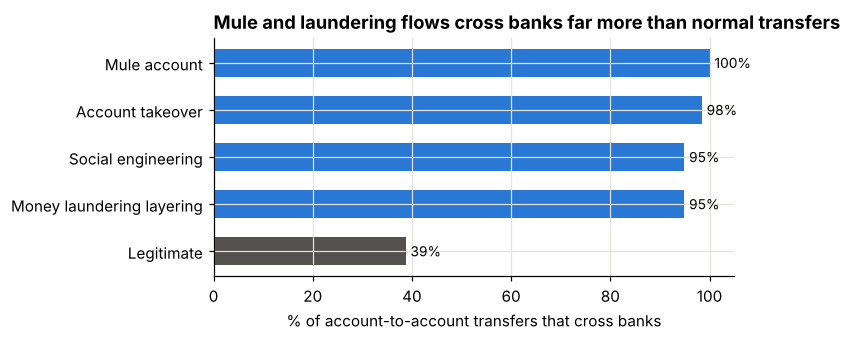

In [5]:
transfers = T[(T.txn_type == "TRANSFER") & (T.dest_bank_id != "EXTERNAL")]
share = transfers.groupby(transfers.fraud_type.where(transfers.is_fraud == 1, "legitimate")).is_cross_bank.mean().mul(100)
share = share.sort_values()
share.index = share.index.str.replace("_app", "").str.replace("_", " ").str.capitalize()
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(share.index, share.values, color=[INK2 if i == "Legitimate" else BLUE for i in share.index], height=0.6)
for i, v in enumerate(share.values):
    ax.text(v + 1, i, f"{v:.0f}%", va="center", fontsize=9)
ax.set_xlabel("% of account-to-account transfers that cross banks")
ax.set_title("Mule and laundering flows cross banks far more than normal transfers")
ax.set_xlim(0, 105)
plt.tight_layout(); plt.show()

## 3. Behavioural signatures

Some fraud types leave almost no trace in the transaction itself. A coerced customer sends money from their own phone, to a new payee, for an amount that looks plausible. What changes is **how** they use the app: long hesitations, slower typing and an active phone call. A remote-access takeover shows the opposite: injected touches with constant pressure and almost no hand motion.

In [7]:
B = T[T.has_behavioural == 1].copy()
B["group"] = B.fraud_type.where(B.is_fraud == 1, "legitimate")
cols = {"pause_count_2s": "pauses > 2 s", "hesitation_ratio": "hesitation ratio", "iki_mean_ms": "inter-key interval (ms)",
        "active_call_flag": "active call (share)", "accel_std_mean": "hand motion", "is_new_device_for_account": "new device (share)"}
sig = B.groupby("group")[list(cols)].agg(lambda s: s.mean() if set(s.dropna().unique()) <= {0, 1} else s.median())
sig.rename(columns=cols).round(3)

,pauses > 2 s,hesitation ratio,inter-key interval (ms),active call (share),hand motion,new device (share)
group,,,,,,
account_takeover,1.000,0.055,396.738,0.045,0.033,0.318
card_not_present,0.043,0.000,77.729,0.043,0.000,0.130
first_party,1.000,0.176,447.172,0.041,0.199,0.020
legitimate,2.000,0.186,412.401,0.045,0.244,0.043
money_laundering_layering,0.000,0.000,59.750,0.000,0.000,0.213
mule_account,1.000,0.071,315.159,0.000,0.256,0.200
social_engineering_app,11.000,0.613,707.314,0.538,0.259,0.051
synthetic_identity,1.000,0.076,350.235,0.025,0.000,0.275


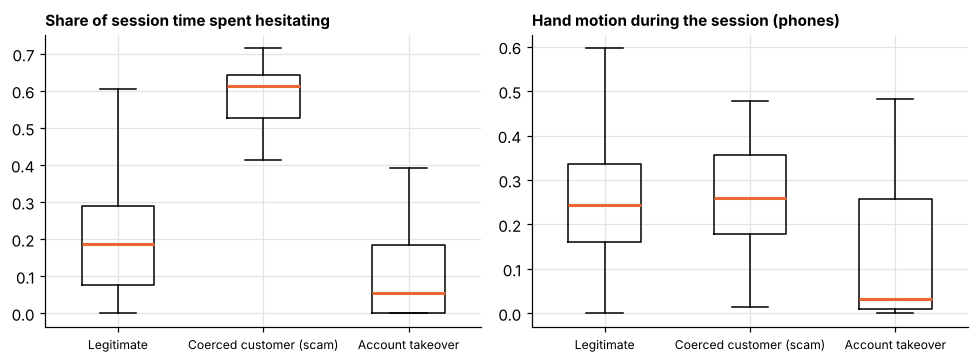

In [8]:
groups = ["legitimate", "social_engineering_app", "account_takeover"]
labels = {"legitimate": "Legitimate", "social_engineering_app": "Coerced customer (scam)", "account_takeover": "Account takeover"}
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
data = [B.loc[B.group == g, "hesitation_ratio"].dropna() for g in groups]
axes[0].boxplot(data, showfliers=False, widths=0.5, medianprops=dict(color=ORANGE, lw=2))
axes[0].set_xticks([1, 2, 3], [labels[g] for g in groups], fontsize=8)
axes[0].set_title("Share of session time spent hesitating", fontsize=10)
data = [B.loc[B.group == g, "accel_std_mean"].dropna() for g in groups]
axes[1].boxplot(data, showfliers=False, widths=0.5, medianprops=dict(color=ORANGE, lw=2))
axes[1].set_xticks([1, 2, 3], [labels[g] for g in groups], fontsize=8)
axes[1].set_title("Hand motion during the session (phones)", fontsize=10)
plt.tight_layout(); plt.show()

## 4. What one bank is allowed to see

Each bank's shard (`clients/BANK_XX/`) holds only its own transactions. Customer IDs are replaced by **bank-specific pseudonyms** and device IDs by **bank-salted hashes**, so two banks cannot join their customers directly. Cross-bank identity has to be learned from behaviour and transaction patterns.

In [10]:
shard = pd.read_csv(os.path.join(BASE, "clients", "BANK_01", "transactions.csv.gz"), low_memory=False)
print("Columns only in the global ground truth:", sorted(set(T.columns) - set(shard.columns)))
print("Columns only in the bank shard:        ", sorted(set(shard.columns) - set(T.columns)))
one = T[(T.bank_id == "BANK_01") & T.device_id.notna()].iloc[0]
row = shard[shard.txn_id == one.txn_id].iloc[0]
print(f"\nSame transaction {one.txn_id}: global customer {one.global_customer_id} -> bank pseudonym {row.local_customer_id}")
print(f"Device {one.device_id} -> bank-salted hash {row.device_hash}")

Columns only in the global ground truth: ['device_id', 'fraud_episode_id', 'global_customer_id']
Columns only in the bank shard:         ['device_hash', 'local_customer_id']

Same transaction TXN_00000087: global customer GC_000588 -> bank pseudonym LC_bd95f14c40
Device DEV_d57ac65e3dce -> bank-salted hash DH_0e10af317211


## 5. Temporal split and drift

Train on January–August, validate on September–October, test on November–December 2024. The test period is deliberately harder: remote-access takeovers and coercion scams grow through the second half, card testing peaks at year end, and one device farm appears only in November. (The sample is small, so its monthly rates are noisy; on the full benchmark fraud prevalence is 0.95% in train, 1.10% in validation and 1.42% in test.)

split
test     1.40
train    0.95
val      1.11
Name: fraud rate %, dtype: float64


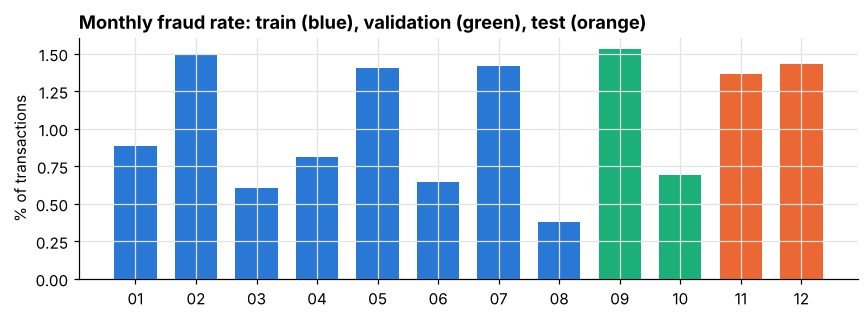

In [12]:
T["month"] = pd.to_datetime(T.timestamp).dt.to_period("M").astype(str)
m = T.groupby("month").is_fraud.mean().mul(100)
fig, ax = plt.subplots(figsize=(8, 3))
colors = [BLUE if mo <= "2024-08" else (AQUA if mo <= "2024-10" else ORANGE) for mo in m.index]
ax.bar(range(len(m)), m.values, color=colors, width=0.7)
ax.set_xticks(range(len(m)), [mo[5:] for mo in m.index])
ax.set_ylabel("% of transactions")
ax.set_title("Monthly fraud rate: train (blue), validation (green), test (orange)")
plt.tight_layout(); plt.show()
print(T.groupby("split").is_fraud.mean().mul(100).round(2).rename("fraud rate %"))

## 6. Raw session events

Besides the 27 aggregated session features, every behavioural session is stored as a sequence of up to 64 raw events (type, time gap, key hold, pressure, touch size, velocity, straightness, motion, screen). This is the input of the behavioural Transformer.

In [14]:
z = np.load(os.path.join(BASE, "clients", "BANK_01", "session_events.npz"))
print("events tensor:", z["events"].shape, "| fields:", [str(f) for f in z["fields"]])
i = int(np.argmax(z["is_fraud"]))
ev = pd.DataFrame(z["events"][i, :z["lengths"][i]].astype(float), columns=z["fields"])
names = {0: "pad", 1: "key", 2: "backspace", 3: "tap", 4: "swipe", 5: "mouse", 6: "paste", 7: "screen", 8: "biometric"}
ev["event_type"] = ev.event_type.astype(int).map(names)
print(f"First 12 events of a fraudulent session ({z['txn_id'][i]}):")
ev.head(12).round(2)

events tensor: (2453, 64, 9) | fields: ['event_type', 'dt_ms', 'hold_ms', 'pressure', 'touch_size', 'velocity', 'straightness', 'accel_std', 'screen_idx']
First 12 events of a fraudulent session (TXN_00002830):


,event_type,dt_ms,hold_ms,pressure,touch_size,velocity,straightness,accel_std,screen_idx
0,screen,0.00,0.00,-1.00,-1.00,-1.0,-1.0,0.64,0.0
1,key,600.50,139.88,0.35,0.43,-1.0,-1.0,0.38,0.0
2,key,402.75,163.62,0.51,0.41,-1.0,-1.0,0.23,0.0
3,backspace,485.25,118.88,0.43,0.32,-1.0,-1.0,0.48,0.0
4,key,28784.00,186.00,0.50,0.40,-1.0,-1.0,0.78,0.0
5,key,714.50,115.62,0.46,0.40,-1.0,-1.0,0.27,0.0
6,key,339.25,147.75,0.53,0.36,-1.0,-1.0,0.74,0.0
7,backspace,562.00,103.50,0.52,0.48,-1.0,-1.0,0.56,0.0
8,key,849.50,112.88,0.58,0.46,-1.0,-1.0,0.52,0.0
9,key,645.00,135.88,0.56,0.36,-1.0,-1.0,0.45,0.0


## Next

- `python generator/validate_dataset.py <dir>` runs the leakage probe and a gradient-boosting baseline on the full benchmark (combined PR-AUC 0.881 on digital sessions). Any new model should be compared against that baseline, not against chance.
- Model results are in `docs/RESULTS.md`; the model code will be released in mid-2027.